In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
# Permite importar `proyecto` sin instalarlo: el código vive en src/
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

# 05 · Torneo de modelos

Objetivo: elegir **uno o dos finalistas** para optimizar, con evidencia y sin abrir la prueba. Reglas:

1. **Mismos datos y mismos pliegues** para todos: los 5 pliegues por `MemberKey` del notebook 04.
2. Una **línea base** que cualquier modelo serio debe vencer.
3. **Guardar cada pliegue** y mirar la variabilidad: una diferencia menor que el ruido no es una victoria.

Todos usan las **variables finales de la etapa 4** (`FINAL_FEATURES`: referencia + puntaje de Prosper + historial en
Prosper; 41 numéricas y 7 categóricas, sin índice climático).

| Candidato | Por qué está |
|---|---|
| Línea base (proporción de impago) | Piso: predice 0,31 para todos. Con la regla de costo equivale a "rechazar a todos" (0,69) |
| Regresión logística | Simple e interpretable; en crédito suele exigirse un modelo explicable |
| Random forest | Ensamble de árboles independientes: robusto y con pocos supuestos |
| LightGBM | Boosting rápido y muy competitivo en datos tabulares (el modelo fijo de la etapa 4) |
| XGBoost | Boosting de referencia para comparar con LightGBM |

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from proyecto.config import GROUP_COL, PROCESSED_DIR, RANDOM_STATE, REPORTS_DIR, TARGET
from proyecto.data.split import group_cv
from proyecto.features.engineering import FINAL_FEATURES
from proyecto.models.train import (build_pipeline, candidates, encode_target, evaluate_folds, feature_frame,
                                   improvement_over_noise)

ID_COL = GROUP_COL
train = pd.read_parquet(PROCESSED_DIR / "train.parquet")
X, y = feature_frame(train), encode_target(train[TARGET])
folds = list(group_cv(n_splits=5, seed=RANDOM_STATE).split(X, y, groups=X[ID_COL]))
for train_idx, valid_idx in folds:
    assert set(X.iloc[train_idx][ID_COL]).isdisjoint(set(X.iloc[valid_idx][ID_COL])), "hay prestatarios en los dos lados"
print(f"{len(X):,} préstamos de entrenamiento · 5 pliegues por {ID_COL} · la prueba sigue cerrada")
print("variables:", FINAL_FEATURES)

39,641 préstamos de entrenamiento · 5 pliegues por MemberKey · la prueba sigue cerrada
variables: {'use_prosper_scores': True, 'use_prosper_history': True, 'group_employment': True, 'exclude': ('TotalProsperPaymentsBilled', 'OpenCreditLines', 'TotalCreditLinespast7years', 'EstimatedReturn', 'ProsperPaymentsOneMonthPlusLate', 'Recommendations', 'PublicRecordsLast12Months', 'CurrentlyInGroup')}


## 1. Correr el torneo

Cada candidato se entrena y valida en los 5 pliegues. Se guarda **cada pliegue**.

In [3]:
per_fold = {}
for name, (model, scale) in candidates().items():
    per_fold[name] = evaluate_folds(build_pipeline(model, scale=scale, **FINAL_FEATURES), X, y, folds)
    f = per_fold[name]
    print(f"{name:36s} AUC-PR = {f.pr_auc.mean():.4f} ± {f.pr_auc.std():.4f}   costo = {f.cost.mean():.4f}"
          f"   ({f.fit_seconds.mean():.0f} s por ajuste)")
pd.concat(per_fold, names=["modelo"]).to_csv(REPORTS_DIR / "05_torneo_pliegues.csv")

línea base (proporción de impago)    AUC-PR = 0.3104 ± 0.0001   costo = 0.6896   (1 s por ajuste)


regresión logística                  AUC-PR = 0.5850 ± 0.0078   costo = 0.5366   (2 s por ajuste)


random forest                        AUC-PR = 0.6045 ± 0.0125   costo = 0.5277   (12 s por ajuste)


lightgbm                             AUC-PR = 0.6107 ± 0.0100   costo = 0.5167   (2 s por ajuste)


xgboost                              AUC-PR = 0.6104 ± 0.0139   costo = 0.5157   (4 s por ajuste)


## 2. Tabla de negocio

- **AUC-PR de impago** (principal): qué tan arriba quedan los impagos en la lista de revisión.
- **Costo esperado por préstamo** con la matriz 4 a 1 y la regla de menor costo (marcar impago si P > 0,2).
  Hay que vencer 0,69 (rechazar a todos).
- **Costo con umbral 0,5** (decidir por la clase más probable): sirve para ver cuánto aporta la regla de menor costo,
  como en el ejemplo del curso.

In [4]:
def mean(col):
    return {n: f[col].mean() for n, f in per_fold.items()}

def std(col):
    return {n: f[col].std() for n, f in per_fold.items()}

summary = pd.DataFrame({
    "AUC-PR": mean("pr_auc"), "± AUC-PR": std("pr_auc"),
    "costo 4 a 1": mean("cost"), "± costo": std("cost"),
    "costo con umbral 0,5": mean("cost_argmax"),
    "segundos por ajuste": mean("fit_seconds"),
}).sort_values("AUC-PR", ascending=False)
summary.to_csv(REPORTS_DIR / "05_torneo_tabla.csv")
summary.round(4)

,AUC-PR,± AUC-PR,costo 4 a 1,± costo,"costo con umbral 0,5",segundos por ajuste
lightgbm,0.6107,0.0100,0.5167,0.0090,0.8185,2.0429
xgboost,0.6104,0.0139,0.5157,0.0134,0.8228,4.0415
random forest,0.6045,0.0125,0.5277,0.0074,0.8703,11.7008
regresión logística,0.5850,0.0078,0.5366,0.0123,0.8685,1.8358
línea base (proporción de impago),0.3104,0.0001,0.6896,0.0001,1.2415,0.7916


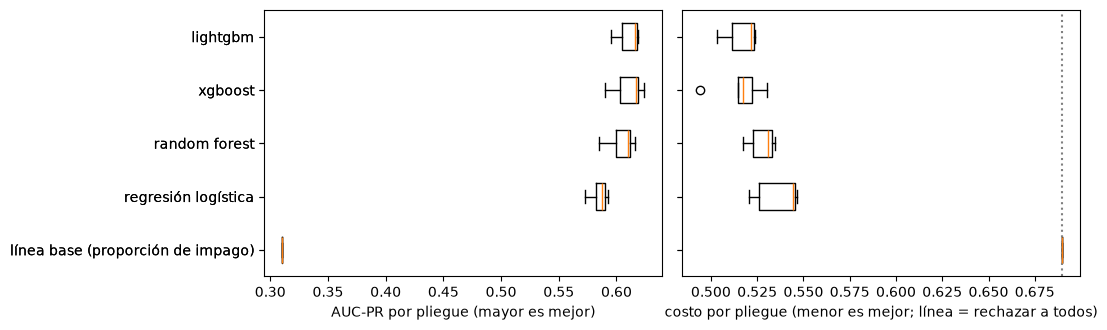

In [5]:
order = summary.index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
axes[0].boxplot([per_fold[n].pr_auc for n in order], vert=False, tick_labels=order, widths=0.5)
axes[0].set_xlabel("AUC-PR por pliegue (mayor es mejor)")
axes[1].boxplot([per_fold[n].cost for n in order], vert=False, tick_labels=order, widths=0.5)
baseline_cost = summary.loc["línea base (proporción de impago)", "costo 4 a 1"]
axes[1].axvline(baseline_cost, color="grey", linestyle=":"); axes[1].set_xlabel("costo por pliegue (menor es mejor; línea = rechazar a todos)")
axes[0].invert_yaxis(); plt.tight_layout(); plt.show()

## 3. Métricas técnicas

| Métrica | Qué mide |
|---|---|
| **ROC-AUC** | Qué tan bien ordena impagos frente a pagados: 0,5 es azar, 1 es perfecto |
| **Log loss y Brier** | Calidad de las probabilidades (menor es mejor). Importa porque la decisión usa P > 0,2 |
| **Recall de impago** | De los que **sí** cayeron en impago, qué proporción marcó el modelo |
| **Precisión de impago** | De los que el modelo **marcó**, cuántos cayeron en impago |
| **F1 de impago** | Equilibrio entre las dos anteriores |
| **% marcado para revisión** | Qué parte de las solicitudes le llega al analista (carga de trabajo) |

Las de ranking (AUC-PR, ROC-AUC) usan las probabilidades; las de clasificación usan la decisión de menor costo.

In [6]:
technical = pd.DataFrame({
    "ROC-AUC": mean("roc_auc"), "log loss": mean("log_loss"), "Brier": mean("brier"),
    "recall impago": mean("recall_default"), "precisión impago": mean("precision_default"),
    "F1 impago": mean("f1_default"), "% marcado para revisión": mean("flagged_rate"),
}).loc[order]
technical.to_csv(REPORTS_DIR / "05_torneo_tecnicas.csv")
technical.round(3)

,ROC-AUC,log loss,Brier,recall impago,precisión impago,F1 impago,% marcado para revisión
lightgbm,0.775,0.510,0.170,0.870,0.432,0.577,0.625
xgboost,0.775,0.510,0.170,0.872,0.432,0.577,0.627
random forest,0.769,0.516,0.172,0.904,0.407,0.561,0.690
regresión logística,0.758,0.524,0.176,0.878,0.414,0.563,0.658
línea base (proporción de impago),0.500,0.619,0.214,1.000,0.310,0.474,1.000


### ¿Coinciden los rankings de negocio y técnico? (1 = mejor)

In [7]:
ranking = pd.DataFrame({
    "AUC-PR (principal)": summary["AUC-PR"].rank(ascending=False),
    "costo (negocio)": summary["costo 4 a 1"].rank(),
    "ROC-AUC": technical["ROC-AUC"].rank(ascending=False),
    "log loss": technical["log loss"].rank(),
    "F1 impago": technical["F1 impago"].rank(ascending=False),
}).loc[order].astype(int)
display(ranking)
print("Mejor por AUC-PR:", summary["AUC-PR"].idxmax(), "| por costo:", summary["costo 4 a 1"].idxmin(),
      "| por ROC-AUC:", technical["ROC-AUC"].idxmax(), "| por log loss:", technical["log loss"].idxmin())

,AUC-PR (principal),costo (negocio),ROC-AUC,log loss,F1 impago
lightgbm,1,2,1,1,2
xgboost,2,1,2,2,1
random forest,3,3,3,3,4
regresión logística,4,4,4,4,3
línea base (proporción de impago),5,5,5,5,5


Mejor por AUC-PR: lightgbm | por costo: xgboost | por ROC-AUC: lightgbm | por log loss: lightgbm


## 4. ¿La diferencia entre los mejores es real?

Todos se evaluaron en **los mismos pliegues**: se compara pliegue a pliegue. "De a pares" = diferencia media /
desviación de la diferencia. Una diferencia que gana los 5 pliegues y es varias veces su ruido es consistente; una
que gana 3 de 5 es un empate práctico.

In [8]:
top = [n for n in order if "línea base" not in n][:3]
pairs = []
for i in range(len(top)):
    for j in range(i + 1, len(top)):
        pr = improvement_over_noise(per_fold[top[j]].pr_auc, per_fold[top[i]].pr_auc)
        cost = improvement_over_noise(per_fold[top[j]].cost, per_fold[top[i]].cost, higher_is_better=False)
        pairs.append({
            "mejor": top[i], "contra": top[j],
            "diferencia AUC-PR": pr["mejora"], "pliegues que gana (AUC-PR)": f"{pr['pliegues ganados']} de 5",
            "de a pares (AUC-PR)": pr["mejora / ruido de a pares"],
            "ahorro de costo": cost["mejora"], "pliegues que gana (costo)": f"{cost['pliegues ganados']} de 5",
            "de a pares (costo)": cost["mejora / ruido de a pares"],
        })
pd.DataFrame(pairs).round(4)

,mejor,contra,diferencia AUC-PR,pliegues que gana (AUC-PR),de a pares (AUC-PR),ahorro de costo,pliegues que gana (costo),de a pares (costo)
0,lightgbm,xgboost,0.0002,2 de 5,0.0591,-0.001,3 de 5,-0.1299
1,lightgbm,random forest,0.0062,5 de 5,1.9475,0.011,5 de 5,5.6460
2,xgboost,random forest,0.0060,5 de 5,2.5054,0.012,5 de 5,1.4565


## 5. ¿Cuánto vale la diferencia?

El costo está en unidades: **1 unidad = rechazar a un buen cliente ≈ 1.154,30 USD** de intereses y cargos que se dejan
de ganar (medido en `notebooks/01_caso_negocio.ipynb`). Es una aproximación: los intereses no son la ganancia neta del
inversionista. Se expresa **por cada 1.000 solicitudes revisadas**.

In [9]:
USD_PER_UNIT = 1154.30
PER = 1_000
base = "línea base (proporción de impago)"
cheapest = summary["costo 4 a 1"].idxmin()
money = pd.DataFrame({
    "costo por solicitud (unidades)": summary["costo 4 a 1"],
    "costo por 1.000 solicitudes (USD)": summary["costo 4 a 1"] * PER * USD_PER_UNIT,
    "ahorro vs. línea base (USD)": (summary.loc[base, "costo 4 a 1"] - summary["costo 4 a 1"]) * PER * USD_PER_UNIT,
    "extra vs. el de menor costo (USD)": (summary["costo 4 a 1"] - summary.loc[cheapest, "costo 4 a 1"]) * PER * USD_PER_UNIT,
})
money.style.format({"costo por solicitud (unidades)": "{:.3f}", **{c: "{:,.0f}" for c in money.columns[1:]}})

,costo por solicitud (unidades),costo por 1.000 solicitudes (USD),ahorro vs. línea base (USD),extra vs. el de menor costo (USD)
lightgbm,0.517,"596,440","199,582","1,164"
xgboost,0.516,"595,276","200,746",0
random forest,0.528,"609,165","186,857","13,889"
regresión logística,0.537,"619,385","176,637","24,110"
línea base (proporción de impago),0.690,"796,022",0,"200,746"


## 6. Lectura y finalistas

Variables: el conjunto final **revisado** de la etapa 4 (34 numéricas y 6 categóricas).

**Lo que muestran los números:**

- **Todos los modelos superan con holgura a la línea base.** La línea base tiene AUC-PR 0,310 y costo 0,690; el
  peor modelo real (regresión logística) logra 0,585 y 0,537.
- **LightGBM y XGBoost empatan.** En AUC-PR, LightGBM gana por +0,0002 en solo 2 de 5 pliegues (de a pares
  0,06). En costo, XGBoost cuesta 0,001 menos y gana 3 de 5 (de a pares 0,13). Los dos tienen ROC-AUC 0,775 y log loss 0,510: ordenan
  y deciden igual.
- **Random forest pierde contra los dos boosting en los 5 pliegues** (−0,006 de AUC-PR; de a pares 1,9 y 2,5) y
  tarda 4 veces más que LightGBM (10 s contra 2 s).
- **La regresión logística queda 0,026 de AUC-PR por debajo.** Es el precio de la interpretabilidad: unos 24.100 USD
  más por cada 1.000 solicitudes que el mejor.
- **La regla de decisión vale tanto como el modelo.** Si se decidiera por la clase más probable (umbral 0,5), LightGBM
  costaría **0,82** por solicitud, **más que rechazar a todos** (0,69), porque dejaría pasar demasiados impagos. Con la
  regla de menor costo (P > 0,2) cuesta 0,52. Eso vale ≈ 350.000 USD por cada 1.000 solicitudes. Lo mismo pasa con todos
  los modelos.
- **Los rankings casi coinciden.** LightGBM es primero en AUC-PR, ROC-AUC y log loss, y XGBoost en costo y F1, con
  diferencias muy por debajo del ruido.

**En dinero** (aproximado, 1 unidad ≈ 1.154,30 USD), por cada 1.000 solicitudes: XGBoost ahorra ≈ 200.700 USD y
LightGBM ≈ 199.600 USD frente a rechazar a todos. La diferencia entre los dos (≈ 1.200 USD) está dentro del ruido.

**Finalistas para la optimización: LightGBM y XGBoost.**

| Finalista | Por qué | Qué podría cambiar con la optimización |
|---|---|---|
| LightGBM | Primero en AUC-PR (empatado) y el más rápido de los dos (2 s): permite más ensayos con el mismo presupuesto | Regularización (`min_child_samples`, `reg_lambda`) y tamaño de los árboles |
| XGBoost | Primero en costo (empatado) | Profundidad y `min_child_weight`; es más lento (4 s) |

**Descartados:** random forest (pierde los 5 pliegues y es más lento) y regresión logística (−0,026 de AUC-PR; queda
como referencia interpretable).

**Por qué el torneo no elige un campeón:** la diferencia entre los dos primeros es menor que el ruido entre pliegues. La
optimización puede cambiar el orden, y solo la prueba final (etapa 7) dice qué tan bueno es el modelo elegido.

### Un efecto que la métrica principal no ve: la carga del analista

Con la matriz 4 a 1, la regla de menor costo marca como "revisar" toda solicitud con P(impago) > 0,2. Así, los dos
mejores modelos **envían a revisión el 63 % de las solicitudes**: detectan el 87 % de los impagos, pero solo el 43 %
de las marcadas cae en impago. Si el equipo de riesgo no puede revisar ese volumen, hará falta un umbral por
capacidad. Se decide en la etapa 7, con validación.

**Siguiente:** `06_optimizacion.ipynb`.